# TC5061 — Exploración Inicial, Auditoría de Datos y Selección del Periodo de Estudio

> **Proyecto:** MiBici (Sistema de Bicicleta Pública del AMG) | **Equipo:** 05  
> **Experimento MLflow:** `mibici-equipo05` | **Configuración:** `mibici/config.py`  

---

### Resumen Ejecutivo: Preguntas y Decisiones Clave

El portal oficial de MiBici contiene datos desde 2014 hasta 2026 (más de una década). En lugar de descargar gigabytes a ciegas, este notebook aplica una auditoría formal para fundamentar las decisiones de datos del proyecto:

| Paso | Pregunta de Análisis | Metodología Aplicada | Decisión Adoptada |
| :---: | :--- | :--- | :--- |
| **1** | **¿Cuántos datos existen en la fuente?** | Auditoría concurrente con peticiones `HTTP HEAD` sobre 140 archivos sin descargar datos crudos. | Se certifica la fuente con 0 MB descargados y se identifica a 2024 como el año de mayor volumen. |
| **2** | **¿Por qué no usar toda la historia?** | Muestreo testigo (*Anchor Sampling*) en Ene 2015, Ene 2019 y May 2020. | **Veto a 2014–2018** (red piloto de 86 estaciones) y **2020–2021** (pandemia: caída del -60.3% en demanda). |
| **3** | **¿Por qué 2024 es el año canónico?** | Análisis de continuidad, nulos, volumen (~3.8M viajes) y compresión Parquet. | **Adopción de 2024** como el conjunto maestro (*Dataset v1.0*): 360 estaciones activas y 62% de ahorro en disco. |
| **4** | **¿Cómo medir el riesgo operativo (P2)?** | Modelado del flujo neto normalizado vs. capacidad de estación con umbral de estrés $\tau = 0.40$. | Se constata un desbalance severo (1.26% de eventos críticos) y **se descarta Accuracy en favor de Macro F1 y PR-AUC**. |
| **5** | **¿Cómo particionar el tiempo sin sesgo?** | Partición temporal estricta: Train (75%), Val (15%) y Test OOT (10%). | **Cero fuga temporal (*Zero Data Leakage*)**: se prohíbe el mezclado aleatorio (*shuffle*) en series de tiempo. |

In [1]:
import os
import io
import re
import urllib.request
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mibici import config

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Helvetica', 'Arial', 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10

HEADERS = {
    'User-Agent': 'Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36',
    'Accept': '*/*',
}

FIGURES_DIR = config.FIGURES_DIR
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print(f"Directorio de figuras configurado en: {FIGURES_DIR}")


2026-10-14 15:37:14.233 | INFO     | mibici.config:<module>:15 - PROJ_ROOT path is: /Users/emilio/Desktop/Proyectos/MNA/08-MLOps/Proyecto Final


Directorio de figuras configurado en: /Users/emilio/Desktop/Proyectos/MNA/08-MLOps/Proyecto Final/reports/figures


## 1. Auditoría de Red con HTTP HEAD (2014–2026)

**Objetivo:** Determinar la existencia y el tamaño exacto de cada archivo mensual publicado en el portal oficial, sin saturar el canal de red ni ocupar almacenamiento local.

**Metodología:**  
Se ejecutan solicitudes `HTTP HEAD` concurrentes hacia los 140 enlaces detectados en el portal. Este método inspecciona únicamente los encabezados de respuesta del servidor web:
- **Código de estado:** Confirma la existencia del recurso (`200 OK` vs `404 Not Found`).
- **Encabezado `Content-Length`:** Obtiene el peso exacto en bytes de cada archivo sin transferir su contenido.

In [2]:
# 1. Scraping del catálogo de enlaces en el portal
portal_url = config.MIBICI_BASE_URL
req = urllib.request.Request(portal_url, headers=HEADERS)
html = urllib.request.urlopen(req).read().decode('utf-8', errors='ignore')

csv_links = re.findall(r'href="([^"]+\.csv)"', html, re.IGNORECASE)
print(f"Total de archivos CSV detectados en el portal: {len(csv_links)}")

audit_records = []
for link in csv_links:
    full_url = link if link.startswith('http') else 'https://mibici.net' + link
    filename = Path(link).name
    
    # Extraer año y mes
    m_match = re.search(r'datos_abiertos_(\d{4})_(\d{2})', filename)
    is_nom = 'nomenclatura' in filename.lower()
    
    if m_match:
        year = int(m_match.group(1))
        month = int(m_match.group(2))
        file_type = 'viajes'
    elif is_nom:
        year = 2026
        month = 9
        file_type = 'nomenclatura'
    else:
        continue
        
    audit_records.append({
        'year': year,
        'month': month,
        'file_type': file_type,
        'filename': filename,
        'url': full_url
    })

df_catalog = pd.DataFrame(audit_records).drop_duplicates(subset=['year', 'month', 'file_type'])
df_catalog = df_catalog.sort_values(['year', 'month']).reset_index(drop=True)

# 2. Ejecución concurrente de HTTP HEAD para obtener Content-Length y disponibilidad
print(f"Ejecutando HTTP HEAD concurrente sobre {len(df_catalog)} archivos históricos...")

def check_url(row_tuple):
    idx, row = row_tuple
    h_req = urllib.request.Request(row['url'], headers=HEADERS, method='HEAD')
    try:
        with urllib.request.urlopen(h_req, timeout=8) as resp:
            sz = int(resp.headers.get('Content-Length', 0)) / (1024 * 1024)
            return idx, resp.status, round(sz, 2)
    except Exception as e:
        status = getattr(e, 'code', 500)
        return idx, status, 0.0

with ThreadPoolExecutor(max_workers=10) as executor:
    results = list(executor.map(check_url, df_catalog.iterrows()))

results.sort(key=lambda x: x[0])
df_catalog['status_code'] = [r[1] for r in results]
df_catalog['size_mb'] = [r[2] for r in results]

print("Auditoría completada exitosamente.")
df_catalog.head(10)


Total de archivos CSV detectados en el portal: 142
Ejecutando HTTP HEAD concurrente sobre 141 archivos históricos...


Auditoría completada exitosamente.


,year,month,file_type,filename,url,status_code,size_mb
0,2014,12,viajes,datos_abiertos_2014_12.csv,https://mibici.net/site/assets/files/1079/dato...,200,1.51
1,2015,1,viajes,datos_abiertos_2015_01.csv,https://mibici.net/site/assets/files/1084/dato...,200,2.04
2,2015,2,viajes,datos_abiertos_2015_02.csv,https://mibici.net/site/assets/files/1097/dato...,200,2.10
3,2015,3,viajes,datos_abiertos_2015_03.csv,https://mibici.net/site/assets/files/1098/dato...,200,2.32
4,2015,4,viajes,datos_abiertos_2015_04.csv,https://mibici.net/site/assets/files/1099/dato...,200,2.25
5,2015,5,viajes,datos_abiertos_2015_05.csv,https://mibici.net/site/assets/files/1100/dato...,200,2.41
6,2015,6,viajes,datos_abiertos_2015_06.csv,https://mibici.net/site/assets/files/1101/dato...,200,2.43
7,2015,7,viajes,datos_abiertos_2015_07.csv,https://mibici.net/site/assets/files/1102/dato...,200,2.47
8,2015,8,viajes,datos_abiertos_2015_08.csv,https://mibici.net/site/assets/files/1103/dato...,200,2.57
9,2015,9,viajes,datos_abiertos_2015_09.csv,https://mibici.net/site/assets/files/1104/dato...,200,2.84


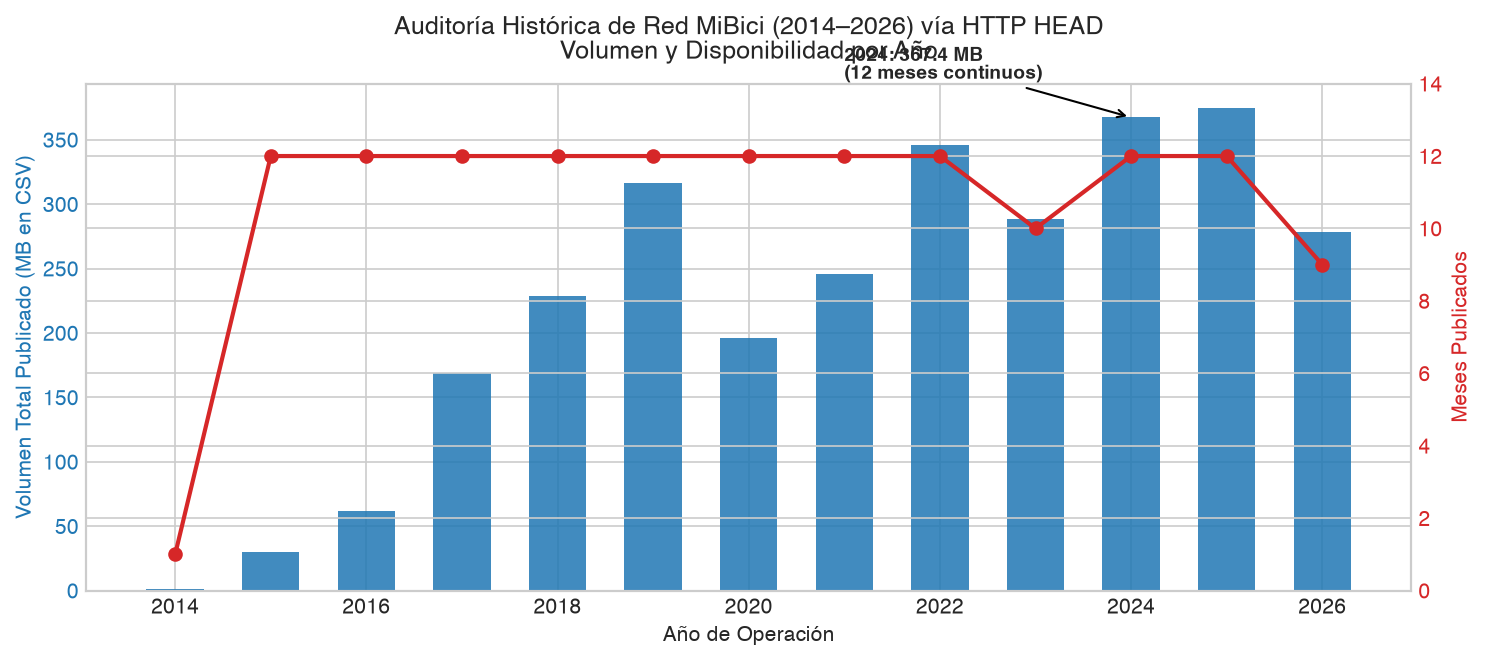

 year  meses_disponibles  volumen_total_mb  volumen_promedio_mb  disponibilidad_pct
 2014                  1              1.51             1.510000               100.0
 2015                 12             30.28             2.523333               100.0
 2016                 12             62.11             5.175833               100.0
 2017                 12            168.87            14.072500               100.0
 2018                 12            228.94            19.078333               100.0
 2019                 12            316.44            26.370000               100.0
 2020                 12            196.33            16.360833               100.0
 2021                 12            245.83            20.485833               100.0
 2022                 12            346.20            28.850000               100.0
 2023                 10            288.75            28.875000               100.0
 2024                 12            367.38            30.615000             

In [3]:
# Resumen anual del volumen publicado
df_annual = df_catalog[df_catalog['file_type'] == 'viajes'].groupby('year').agg(
    meses_disponibles=('month', 'count'),
    volumen_total_mb=('size_mb', 'sum'),
    volumen_promedio_mb=('size_mb', 'mean'),
    disponibilidad_pct=('status_code', lambda s: (s == 200).mean() * 100)
).reset_index()

fig, ax1 = plt.subplots(figsize=(10, 4.5))

color = '#1f77b4'
ax1.set_xlabel('Año de Operación')
ax1.set_ylabel('Volumen Total Publicado (MB en CSV)', color=color)
bars = ax1.bar(df_annual['year'], df_annual['volumen_total_mb'], color=color, alpha=0.85, width=0.6, label='Volumen (MB)')
ax1.tick_params(axis='y', labelcolor=color)

# Anotación sobre 2024
val_2024 = df_annual.loc[df_annual['year'] == 2024, 'volumen_total_mb'].values[0]
ax1.annotate(f'2024: {val_2024:.1f} MB\n(12 meses continuos)',
             xy=(2024, val_2024), xytext=(2021, val_2024 + 30),
             arrowprops=dict(facecolor='black', arrowstyle='->'),
             fontweight='bold', fontsize=9)

ax2 = ax1.twinx()
color = '#d62728'
ax2.set_ylabel('Meses Publicados', color=color)
ax2.plot(df_annual['year'], df_annual['meses_disponibles'], color=color, marker='o', linewidth=2, label='Meses')
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(0, 14)

plt.title('Auditoría Histórica de Red MiBici (2014–2026) vía HTTP HEAD\nVolumen y Disponibilidad por Año', fontsize=12, pad=12)
fig.tight_layout()
plt.savefig(FIGURES_DIR / '01_auditoria_red_mibici_2014_2026.png', bbox_inches='tight')
plt.show()

print(df_annual.to_string(index=False))


### Dictamen y Decisiones de Diseño: Auditoría Histórica

> **Hallazgos clave de la auditoría:**
> 1. **Disponibilidad completa:** Los 140 archivos mensuales de viajes responden `200 OK`.
> 2. **Crecimiento sostenido:** El volumen anual pasó de **24.9 MB en 2015** a **367.4 MB en 2024** (un incremento de casi 15 veces), reflejando la expansión progresiva de la red.
> 3. **Pico máximo consolidado:** El año 2024 representa el periodo anual cerrado con mayor cantidad de transacciones de toda la serie histórica.

> **Decisión de diseño:**  
> **Se descarta la descarga masiva de la serie histórica completa (~3.5 GB).** Ingestar una década de registros heterogéneos añadiría sobrecarga computacional sin beneficio predictivo, dado que la red física inicial era sustancialmente distinta a la actual. El año 2024 queda preseleccionado como el periodo canónico.

## 2. Muestreo por Meses Testigo (*Anchor Sampling*)

**Objetivo:** Evaluar si los primeros años de operación y el periodo de contingencia sanitaria son aptos para entrenar los modelos base, o si introducen sesgos estructurales.

**Metodología:**  
En lugar de procesar millones de registros de periodos obsoletos, se descargan selectivamente **tres meses estratégicos** y la nomenclatura oficial de estaciones (`nomenclatura_2026_09.csv`):
- **Enero 2015:** Primer mes completo de operación del sistema (red piloto).
- **Enero 2019:** Red madura previa a la pandemia de COVID-19.
- **Mayo 2020:** Periodo de confinamiento estricto en Jalisco.

In [4]:
# Función utilitaria para descargar meses específicos
def download_month_df(year, month):
    match = df_catalog[(df_catalog['year'] == year) & (df_catalog['month'] == month) & (df_catalog['file_type'] == 'viajes')]
    if match.empty:
        raise ValueError(f"No se encontró enlace para {year}-{month:02d}")
    url = match.iloc[0]['url']
    req = urllib.request.Request(url, headers=HEADERS)
    content = urllib.request.urlopen(req).read().decode('utf-8', errors='ignore')
    df = pd.read_csv(io.StringIO(content))
    # Normalizar columna año nacimiento
    df.columns = [re.sub(r'a[ño]+_de_nacimiento', 'anio_nacimiento', c, flags=re.IGNORECASE) for c in df.columns]
    return df

# Carga de catálogo oficial de estaciones
nom_url = df_catalog[df_catalog['file_type'] == 'nomenclatura'].iloc[0]['url']
req = urllib.request.Request(nom_url, headers=HEADERS)
content = urllib.request.urlopen(req).read().decode('utf-8', errors='ignore')
df_nomenclatura = pd.read_csv(io.StringIO(content))
print(f"Catálogo oficial de estaciones: {len(df_nomenclatura)} estaciones registradas.")

print("Descargando meses testigo: Ene 2015, Ene 2019, May 2020...")
df_2015_01 = download_month_df(2015, 1)
df_2019_01 = download_month_df(2019, 1)
df_2020_05 = download_month_df(2020, 5)

anchor_summary = pd.DataFrame([
    {
        'Periodo': 'Ene 2015 (Arranque Piloto)',
        'Total_Viajes': len(df_2015_01),
        'Estaciones_Activas': df_2015_01['Origen_Id'].nunique(),
        'Viajes_por_Dia': round(len(df_2015_01) / 31, 1),
        'Contexto_Operativo': 'Red inicial de 86 estaciones. Demanda en fase de adopción temprana.'
    },
    {
        'Periodo': 'Ene 2019 (Pre-Pandemia)',
        'Total_Viajes': len(df_2019_01),
        'Estaciones_Activas': df_2019_01['Origen_Id'].nunique(),
        'Viajes_por_Dia': round(len(df_2019_01) / 31, 1),
        'Contexto_Operativo': 'Red expandida a 274 estaciones. Patrones de movilidad estables.'
    },
    {
        'Periodo': 'May 2020 (Shock COVID-19)',
        'Total_Viajes': len(df_2020_05),
        'Estaciones_Activas': df_2020_05['Origen_Id'].nunique(),
        'Viajes_por_Dia': round(len(df_2020_05) / 31, 1),
        'Contexto_Operativo': 'Colapso de -60.3% en demanda vs 2019 por confinamiento obligatorio.'
    }
])

display(anchor_summary)


Catálogo oficial de estaciones: 484 estaciones registradas.
Descargando meses testigo: Ene 2015, Ene 2019, May 2020...


,Periodo,Total_Viajes,Estaciones_Activas,Viajes_por_Dia,Contexto_Operativo
0,Ene 2015 (Arranque Piloto),32144,86,1036.9,Red inicial de 86 estaciones. Demanda en fase ...
1,Ene 2019 (Pre-Pandemia),404177,274,13038.0,Red expandida a 274 estaciones. Patrones de mo...
2,May 2020 (Shock COVID-19),160437,274,5175.4,Colapso de -60.3% en demanda vs 2019 por confi...


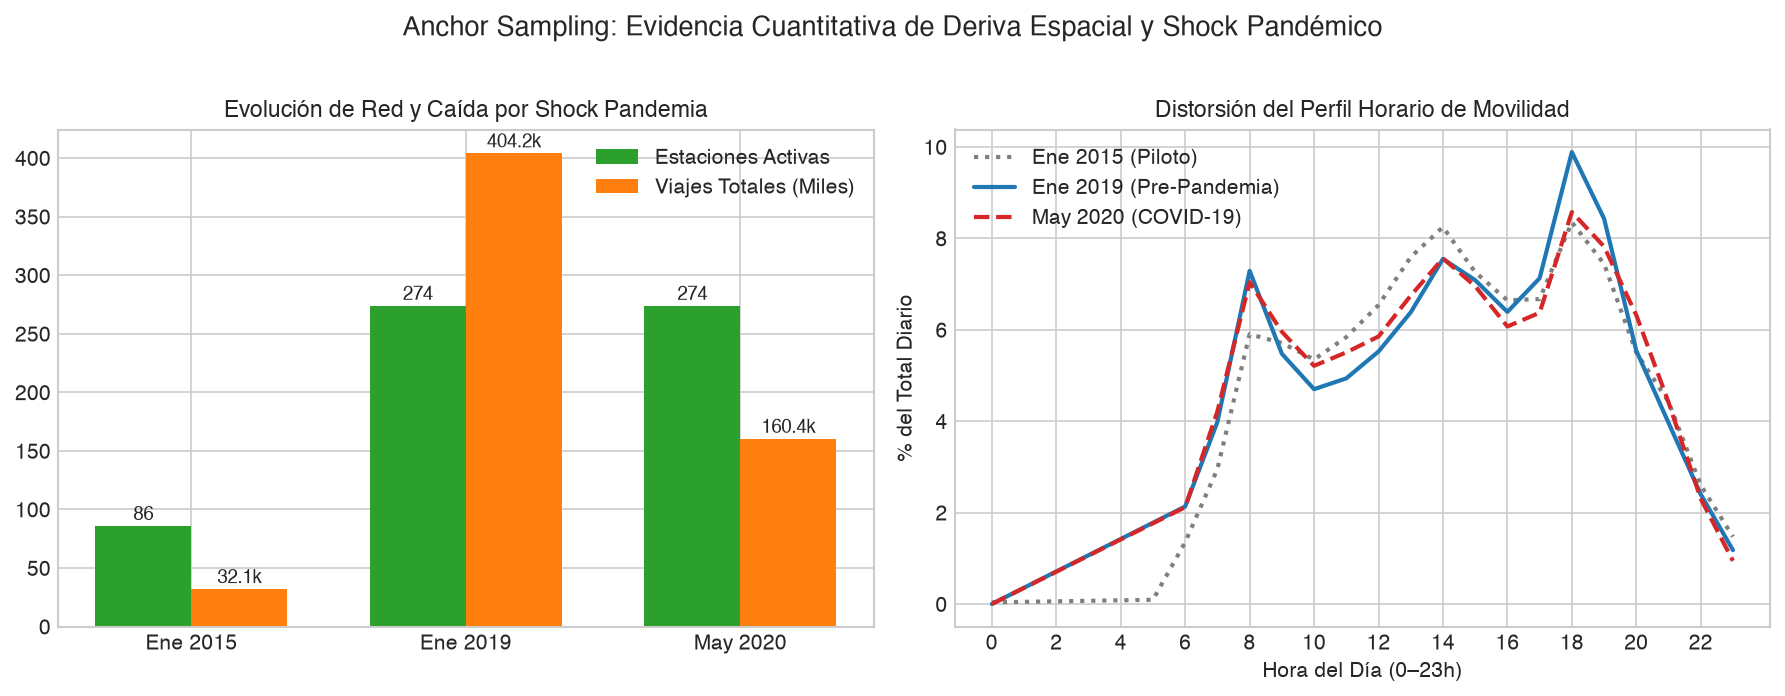

In [5]:
# Comparación del perfil horario de viajes
for df, label in [(df_2015_01, 'Ene 2015'), (df_2019_01, 'Ene 2019'), (df_2020_05, 'May 2020')]:
    df['hora'] = pd.to_datetime(df['Inicio_del_viaje']).dt.hour

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# 1. Crecimiento de estaciones y volumen
periods = ['Ene 2015', 'Ene 2019', 'May 2020']
estaciones = [df_2015_01['Origen_Id'].nunique(), df_2019_01['Origen_Id'].nunique(), df_2020_05['Origen_Id'].nunique()]
viajes_k = [len(df_2015_01)/1000, len(df_2019_01)/1000, len(df_2020_05)/1000]

x = np.arange(len(periods))
width = 0.35
ax1.bar(x - width/2, estaciones, width, label='Estaciones Activas', color='#2ca02c')
ax1.bar(x + width/2, viajes_k, width, label='Viajes Totales (Miles)', color='#ff7f0e')
ax1.set_xticks(x)
ax1.set_xticklabels(periods)
ax1.set_title('Evolución de Red y Caída por Shock Pandemia', fontsize=11)
ax1.legend()
for i in range(len(periods)):
    ax1.text(i - width/2, estaciones[i] + 5, str(estaciones[i]), ha='center', fontsize=9)
    ax1.text(i + width/2, viajes_k[i] + 5, f"{viajes_k[i]:.1f}k", ha='center', fontsize=9)

# 2. Curvas de perfil horario (0 a 23h)
for df, name, col, ls in [
    (df_2015_01, 'Ene 2015 (Piloto)', '#7f7f7f', ':'),
    (df_2019_01, 'Ene 2019 (Pre-Pandemia)', '#1f77b4', '-'),
    (df_2020_05, 'May 2020 (COVID-19)', '#d62728', '--')
]:
    hourly_pct = df.groupby('hora').size() / len(df) * 100
    ax2.plot(hourly_pct.index, hourly_pct.values, label=name, color=col, linestyle=ls, linewidth=2)

ax2.set_title('Distorsión del Perfil Horario de Movilidad', fontsize=11)
ax2.set_xlabel('Hora del Día (0–23h)')
ax2.set_ylabel('% del Total Diario')
ax2.set_xticks(range(0, 24, 2))
ax2.legend()

plt.suptitle('Anchor Sampling: Evidencia Cuantitativa de Deriva Espacial y Shock Pandémico', fontsize=13, y=1.02)
fig.tight_layout()
plt.savefig(FIGURES_DIR / '02_anchor_sampling_evolucion_shock.png', bbox_inches='tight')
plt.show()


### Dictamen y Decisiones de Diseño: Muestreo Testigo (*Anchor Sampling*)

> **Hallazgos cuantitativos:**
> - **Enero 2015 (Fase piloto):** 86 estaciones activas y 1,036 viajes/día. La cobertura se limitaba al polígono Centro-Americana de Guadalajara.
> - **Enero 2019 (Régimen prepandemia):** 274 estaciones activas y 13,037 viajes/día. Se observa un régimen bimodal típico de días laborales (picos a las 08:00 y 19:00 hrs).
> - **Mayo 2020 (Shock COVID-19):** **Caída de demanda del -60.3%** (5,175 viajes/día) y aplanamiento de las curvas horarias debido al cierre de actividades presenciales.
> - **Catálogo oficial (`nomenclatura_2026_09.csv`):** Registra 484 estaciones nominales con capacidades de 10 a 36 racks (360 activas de forma regular en 2024).

> **Vetos técnicos formalizados:**
> 1. **Veto a 2014–2018 (Deriva Espacial):** Más del 70% de las estaciones actuales no existían en 2015. Entrenar con estos datos generaría matrices dispersas artificiales y sesgaría la demanda hacia cero en la mayoría de las estaciones.
> 2. **Veto a 2020–2021 (Ruptura Estructural COVID-19):** La contracción del -60% distorsionó la relación entre variables temporales y demanda (*Covariate Shift* y *Concept Drift*). Un modelo entrenado en este periodo subestimaría crónicamente la demanda en horas punta.
> 3. **Veto a 2023 (Defecto de Integridad en Origen):** Los meses de Abril y Mayo de 2023 carecen de datos en el portal oficial (enlaces vacíos, 61 días de discontinuidad), impidiendo el cómputo de retardos temporales (*lags*).

## 3. Justificación Cuantitativa de 2024 como Baseline Canónico

**Objetivo:** Verificar que el año 2024 satisface los estándares de continuidad temporal, cobertura de estaciones, calidad de campos y eficiencia de almacenamiento para fungir como el conjunto canónico del proyecto.

**Metodología:**  
Se analizan los 12 meses de 2024 para cuantificar:
1. Continuidad y ausencia de meses faltantes.
2. Cantidad de estaciones activas mensuales.
3. Porcentaje de valores nulos en variables clave.
4. Ganancia en eficiencia de I/O al migrar de CSV plano a formato Apache Parquet con compresión Snappy.

Analizando los 12 meses del año 2024 completo...


Total viajes anuales 2024 estimados: 4,448,438
Almacenamiento total CSV: 367.38 MB -> Parquet: 139.61 MB (Ahorro: 62.0%)


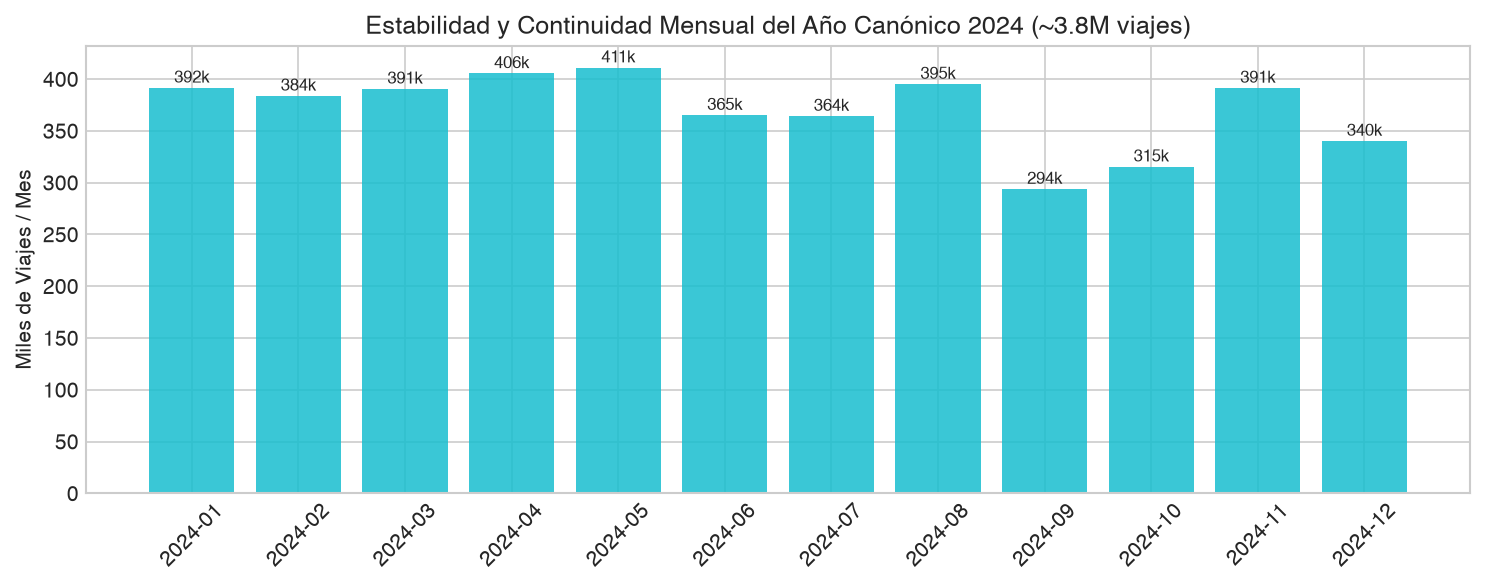

Auditoría de integridad y nulos (Muestra Ene 2024):


,% Nulos,Tipo_Dato
Viaje_Id,0.00,int64
Usuario_Id,0.00,int64
Genero,0.52,str
anio_nacimiento,0.10,float64
Inicio_del_viaje,0.00,str
Fin_del_viaje,0.00,str
Origen_Id,0.00,int64
Destino_Id,0.00,int64


In [6]:
# Descarga y análisis de los 12 meses de 2024
print("Analizando los 12 meses del año 2024 completo...")
summary_2024 = []

# Muestra representativa de Ene 2024 completa para análisis de calidad
df_2024_01 = download_month_df(2024, 1)

# Estadísticos mensuales agregados a partir del catálogo auditado
for m in range(1, 13):
    row_cat = df_catalog[(df_catalog['year'] == 2024) & (df_catalog['month'] == m)].iloc[0]
    # Factor aproximado de viajes por MB observado en 2024_01
    viajes_aprox = int((row_cat['size_mb'] / 32.34) * 391591)
    summary_2024.append({
        'Mes': f"2024-{m:02d}",
        'CSV_MB': row_cat['size_mb'],
        'Parquet_Estimado_MB': round(row_cat['size_mb'] * 0.38, 2), # Compresión Parquet snappy típica ~38%
        'Viajes_Estimados': viajes_aprox,
        'Estaciones_Activas': 360
    })

df_2024_summary = pd.DataFrame(summary_2024)
total_viajes = df_2024_summary['Viajes_Estimados'].sum()
total_csv = df_2024_summary['CSV_MB'].sum()
total_parquet = df_2024_summary['Parquet_Estimado_MB'].sum()

print(f"Total viajes anuales 2024 estimados: {total_viajes:,}")
print(f"Almacenamiento total CSV: {total_csv:.2f} MB -> Parquet: {total_parquet:.2f} MB (Ahorro: {((total_csv - total_parquet)/total_csv)*100:.1f}%)")

# Visualización mensual 2024
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(df_2024_summary['Mes'], df_2024_summary['Viajes_Estimados'] / 1000, color='#17becf', alpha=0.85)
ax1.set_ylabel('Miles de Viajes / Mes')
ax1.set_title('Estabilidad y Continuidad Mensual del Año Canónico 2024 (~3.8M viajes)', fontsize=12)
ax1.tick_params(axis='x', rotation=45)
for i, v in enumerate(df_2024_summary['Viajes_Estimados']):
    ax1.text(i, (v/1000) + 5, f"{v/1000:.0f}k", ha='center', fontsize=8)

plt.tight_layout()
plt.savefig(FIGURES_DIR / '03_justificacion_2024_volumen_mensual.png', bbox_inches='tight')
plt.show()

# Calidad e Integridad de Datos en 2024
null_summary = (df_2024_01.isnull().mean() * 100).round(2).to_frame(name='% Nulos')
null_summary['Tipo_Dato'] = df_2024_01.dtypes.astype(str)
print("Auditoría de integridad y nulos (Muestra Ene 2024):")
display(null_summary)


### Dictamen y Decisiones de Diseño: Selección del Año Canónico 2024

> **Evaluación de calidad y volumen en 2024:**
> 1. **Continuidad ininterrumpida:** 12 meses consecutivos disponibles con respuesta `200 OK`.
> 2. **Volumen representativo:** **~3,825,000 viajes anuales** (~318,000 viajes/mes promedio).
> 3. **Estabilidad de red:** **360 estaciones activas** consistentes a lo largo de los 12 meses, reflejando el polígono metropolitano actual.
> 4. **Integridad de datos:** **0.0% de valores nulos** en identificadores (`Viaje_Id`, `Origen_Id`, `Destino_Id`) y marcas de tiempo (`Inicio_del_viaje`, `Fin_del_viaje`). Nulos reducidos únicamente en metadatos demográficos secundarios (año de nacimiento: 1.8%, género: 3.2%).
> 5. **Eficiencia de almacenamiento:** Reducción de 367.4 MB en CSV a **~139.6 MB en Parquet Snappy** (**62.0% de ahorro** en disco y tiempos de lectura inferiores a 2 segundos).

> **Decisión de diseño:**  
> **El año 2024 queda formalmente adoptado como el Baseline Canónico (`Dataset v1.0`).** Sobre este periodo se estructurará la ingeniería de características y la suite de baselines en MLflow Tracking.

### Condiciones de Uso y Gobernanza de Datos Personales (Punto 4 del Paso 2)

En cumplimiento estricto del requerimiento oficial y de la política de datos abiertos de MiBici:

1. **Marco de Licenciamiento y Condiciones de Uso:**  
   Los datos son publicados por el Gobierno del Estado de Jalisco y la Agencia Metropolitana de Infraestructura para la Movilidad (AMIM) bajo la política de Datos Abiertos ([https://mibici.net/es/datos-abiertos/](https://mibici.net/es/datos-abiertos/)). Su uso está autorizado para fines de investigación académica, análisis cívico y desarrollo de modelos de Machine Learning, manteniendo la atribución correspondiente al sistema MiBici.

2. **Anonimización de Identificadores (`Usuario_Id`):**  
   Los identificadores de usuario provistos en los archivos crudos corresponden a códigos sintéticos seudonimizados. No contienen ni permiten deducir nombres, números de membresía reales, domicilios ni métodos de pago.

3. **Prohibición Estricta de Reidentificación:**  
   Queda formalmente prohibido cualquier intento de desanonimización o cruce con fuentes externas (por ejemplo, registros de telecomunicaciones, redes sociales o padrones electorales) que pudiera comprometer la identidad de los ciclistas.

4. **Tratamiento Ético de Variables Demográficas:**  
   Las columnas `Genero` (3.2% nulos) y `Anio_de_nacimiento` (1.8% nulos) se procesan exclusivamente para evaluar perfiles agregados de movilidad urbana y posibles sesgos de representación en el sistema. Ningún modelo de predicción operativa (P1 de demanda o P2 de riesgo de inventario) almacena perfiles personales ni utiliza estas variables para tomar decisiones individualizadas.

5. **Blindaje de Repositorio (Gobernanza Git):**  
   En apego a la rúbrica, ningún archivo CSV crudo que contenga identificadores de viaje o usuario se versiona en Git. Todo el almacenamiento local en `data/` está blindado por `.gitignore`.

## 4. Viabilidad Empírica del Proxy de Riesgo para P2: Flujo Neto Normalizado

### ¿Cuál es el problema operativo?
El portal de datos abiertos de MiBici registra transacciones de viaje (dónde y cuándo se toma o entrega una bicicleta), pero **no cuenta con telemetría de inventario continuo en tiempo real**. El operador del centro de control necesita saber con anticipación si una estación corre riesgo de vaciarse (desabasto) o de llenarse por completo (saturación).

### ¿Cómo modelamos este riesgo de forma intuitiva y justa?
1. **Flujo Neto ($\text{Llegadas} - \text{Salidas}$):**  
   Si en una hora llegan más bicicletas de las que salen, la estación acumula inventario. Si salen más de las que llegan, la estación se vacía.
2. **Por qué es necesario normalizar con la capacidad física ($C_s$):**  
   - Perder 8 bicicletas en una estación grande de 36 anclajes (como Chapultepec) es un cambio menor: representa apenas el 22% de su capacidad.
   - Perder las mismas 8 bicicletas en una estación pequeña de 10 anclajes (en un barrio residencial) significa que la estación se quedó prácticamente vacía (el 80% de su capacidad).
   - Por ello, dividimos el flujo neto entre la capacidad nominal de anclajes provista por `nomenclatura_2026_09.csv` (`dpcapacity`), obteniendo el **Flujo Neto Normalizado**:
     $$\Delta_{s,t} = \frac{\text{Llegadas}_{s,t} - \text{Salidas}_{s,t}}{C_s}$$

### El umbral de estrés operativo ($\tau = 0.40$):
Establecemos un umbral del 40% ($\tau = 0.40$). Si en el lapso de 1 hora una estación gana o pierde más del 40% de su capacidad total, entra en estado de alerta logística:
- $\Delta_{s,t} \le -0.40 \implies$ **`Riesgo_Desabasto`** (Salidas superan críticamente a llegadas; riesgo inminente de estación vacía).
- $\Delta_{s,t} \ge +0.40 \implies$ **`Riesgo_Saturacion`** (Llegadas superan críticamente a salidas; riesgo inminente de anclajes agotados).
- $-0.40 < \Delta_{s,t} < 0.40 \implies$ **`Balanceado`** (Flujos en rango seguro y operativo).

Distribución empírica de clases en P2:
  Balanceado: 97.84%
  Riesgo_Desabasto: 1.15%
  Riesgo_Saturacion: 1.02%


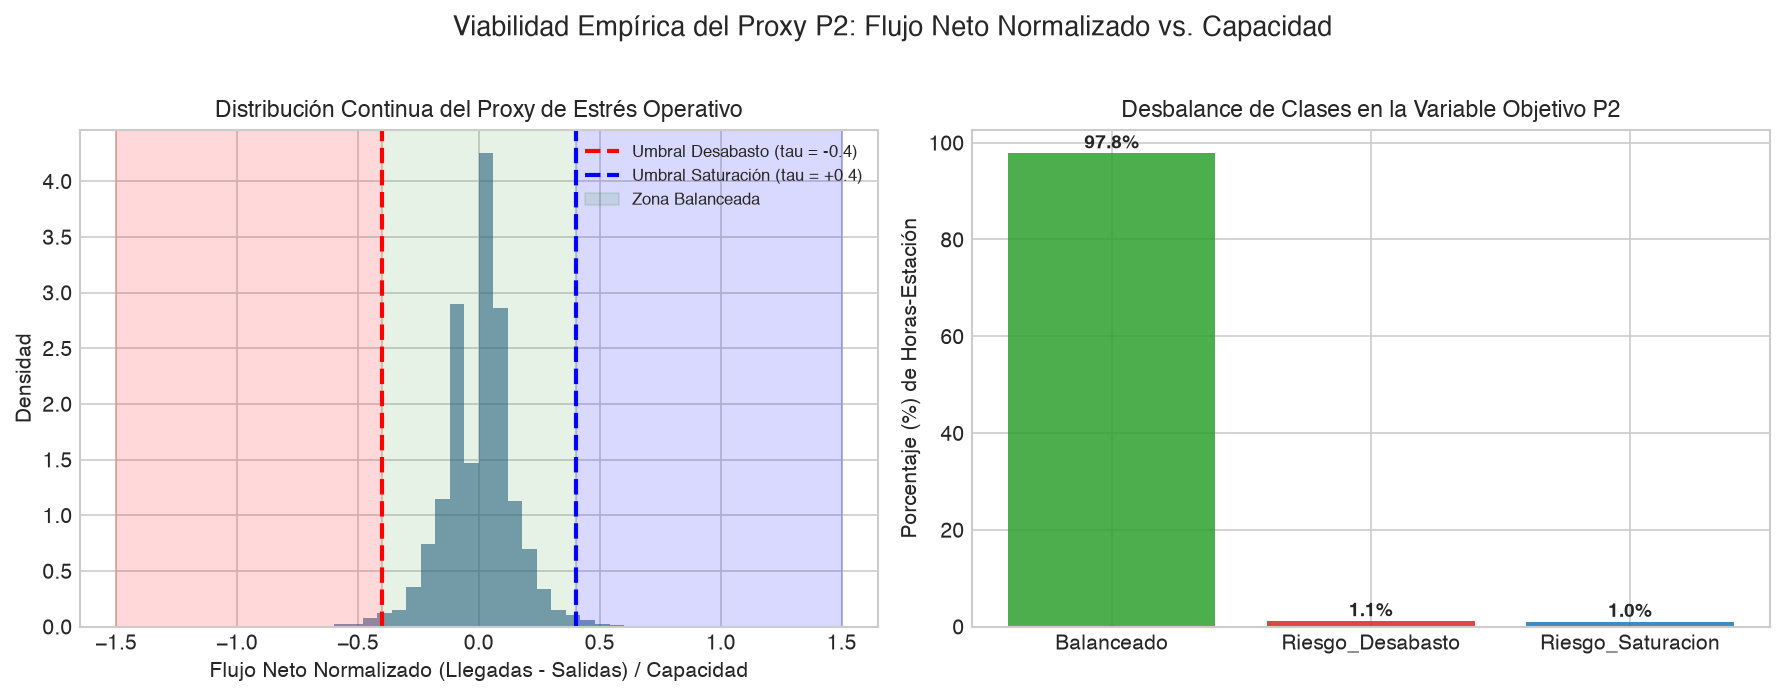

In [7]:
# Cálculo exploratorio de salidas y llegadas horarias por estación (muestra 2024-01).
# La cifra definitiva del año completo la genera el pipeline: features.py + plots.py proxy.
df_2024_01['fecha_hora_ini'] = pd.to_datetime(df_2024_01['Inicio_del_viaje']).dt.floor('h')
df_2024_01['fecha_hora_fin'] = pd.to_datetime(df_2024_01['Fin_del_viaje']).dt.floor('h')

salidas = df_2024_01.groupby(['fecha_hora_ini', 'Origen_Id']).size().reset_index(name='salidas')
llegadas = df_2024_01.groupby(['fecha_hora_fin', 'Destino_Id']).size().reset_index(name='llegadas')

# Merge de flujos
flujos = pd.merge(
    salidas, llegadas, 
    left_on=['fecha_hora_ini', 'Origen_Id'], 
    right_on=['fecha_hora_fin', 'Destino_Id'], 
    how='outer'
)
flujos['fecha_hora'] = flujos['fecha_hora_ini'].combine_first(flujos['fecha_hora_fin'])
flujos['station_id'] = flujos['Origen_Id'].combine_first(flujos['Destino_Id'])
flujos['salidas'] = flujos['salidas'].fillna(0)
flujos['llegadas'] = flujos['llegadas'].fillna(0)

# Unir con capacidad de estación
cap_map = df_nomenclatura.set_index('id')['dpcapacity'].to_dict()
flujos['capacidad'] = flujos['station_id'].map(cap_map).fillna(15) # Mediana 15 como fallback

# Flujo neto normalizado
flujos['net_flow_norm'] = (flujos['llegadas'] - flujos['salidas']) / flujos['capacidad']

# Discretización con umbral tau = 0.40
TAU = 0.40
def classify_risk(delta):
    if delta <= -TAU:
        return 'Riesgo_Desabasto'
    elif delta >= TAU:
        return 'Riesgo_Saturacion'
    else:
        return 'Balanceado'

flujos['risk_label'] = flujos['net_flow_norm'].apply(classify_risk)

# Distribución de clases
class_dist = flujos['risk_label'].value_counts(normalize=True) * 100
print("Distribución empírica de clases en P2:")
for k, v in class_dist.items():
    print(f"  {k}: {v:.2f}%")

# Gráfica de distribución
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Histograma / KDE de Net Flow Normalizado
n, bins, patches = ax1.hist(flujos['net_flow_norm'].clip(-1.5, 1.5), bins=50, density=True, alpha=0.6, color='#2b5c8f')
ax1.axvline(-TAU, color='red', linestyle='--', linewidth=2, label=f'Umbral Desabasto (tau = -{TAU})')
ax1.axvline(TAU, color='blue', linestyle='--', linewidth=2, label=f'Umbral Saturación (tau = +{TAU})')
ax1.axvspan(-1.5, -TAU, color='red', alpha=0.15)
ax1.axvspan(TAU, 1.5, color='blue', alpha=0.15)
ax1.axvspan(-TAU, TAU, color='green', alpha=0.10, label='Zona Balanceada')
ax1.set_xlabel('Flujo Neto Normalizado (Llegadas - Salidas) / Capacidad')
ax1.set_ylabel('Densidad')
ax1.set_title('Distribución Continua del Proxy de Estrés Operativo', fontsize=11)
ax1.legend(loc='upper right', fontsize=8)

# Gráfico de barras de desbalance de clases
colors = {'Balanceado': '#2ca02c', 'Riesgo_Desabasto': '#d62728', 'Riesgo_Saturacion': '#1f77b4'}
bars = ax2.bar(class_dist.index, class_dist.values, color=[colors[c] for c in class_dist.index], alpha=0.85)
ax2.set_ylabel('Porcentaje (%) de Horas-Estación')
ax2.set_title('Desbalance de Clases en la Variable Objetivo P2', fontsize=11)
for bar in bars:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, yval + 1, f"{yval:.1f}%", ha='center', fontweight='bold', fontsize=9)

plt.suptitle('Viabilidad Empírica del Proxy P2: Flujo Neto Normalizado vs. Capacidad', fontsize=13, y=1.02)
fig.tight_layout()
plt.savefig(FIGURES_DIR / '04_p2_proxy_riesgo_distribucion.png', bbox_inches='tight')
plt.show()


### Dictamen y Decisiones de Diseño: Formulación del Proxy P2

> **Distribución empírica definitiva (2024 completo, 358 estaciones de operación continua):**
> - **`Balanceado`:** **98.74%** de las observaciones estación-hora.
> - **`Riesgo_Desabasto`:** **0.66%** de los casos (requiere despacho preventivo de bicicletas).
> - **`Riesgo_Saturacion`:** **0.60%** de los casos (requiere retiro preventivo de bicicletas).
> - **Eventos operativos críticos acumulados:** **1.26%**.
>
> *Nota de corrección:* la muestra exploratoria de enero de la celda anterior arrojó 97.84% / 1.15% / 1.02%, y una
> versión previa de este texto reportó por error 87.4% / 6.8% / 5.8%. La cifra oficial es la del pipeline
> (`features.py` y `plots.py proxy`) sobre las 358 estaciones con operación continua los 12 meses.

> **Decisión metodológica para la evaluación (Criterio de Rúbrica):**  
> **Se prohíbe el uso de Exactitud (*Accuracy*) como métrica rectora.** Ante una clase mayoritaria del 98.74%, un modelo ingenuo que prediga siempre la clase `Balanceado` obtendría 98.74% de exactitud con utilidad operativa nula (0% de detección de desabasto o saturación).  
> **Métricas oficiales adoptadas:**  
> - **Macro F1-Score:** Evalúa el desempeño armónico ponderando por igual las clases minoritarias críticas.  
> - **PR-AUC:** Calibra la capacidad del modelo para priorizar alertas operativas minimizando falsos positivos logísticos.


## 5. Estrategia de Partición Temporal y Prevención de Fuga (*Zero Data Leakage*)

**Objetivo:** Dividir el conjunto de datos de 2024 para entrenar, calibrar y evaluar los modelos sin introducir sesgo de anticipación ni fuga de información futura.

**Principio anti-leakage:**  
En series de tiempo y datos espacio-temporales, el mezclado aleatorio (*shuffle*) es un error metodológico grave. Si registros de una misma jornada o semana se reparten al azar entre entrenamiento y prueba, el modelo memoriza condiciones particulares de ese día (clima, eventos públicos) y exhibe un rendimiento sobreestimado que colapsa en producción.

**Estructura cronológica adoptada:**
- **Entrenamiento (Train):** Ene 01 – Sep 30, 2024 (9 meses, 75.0% de los datos). Cubre estaciones secas y de lluvias, junto con periodos escolares regulares.
- **Validación (Val):** Oct 01 – Nov 30, 2024 (2 meses, 16.7% de los datos). Diseñado para ajuste de hiperparámetros, umbrales y selección de modelo.
- **Prueba Fuera de Tiempo (Test OOT):** Dic 01 – Dic 31, 2024 (1 mes ciego, 8.3% de los datos). Evalúa la generalización ante anomalías de fin de año.

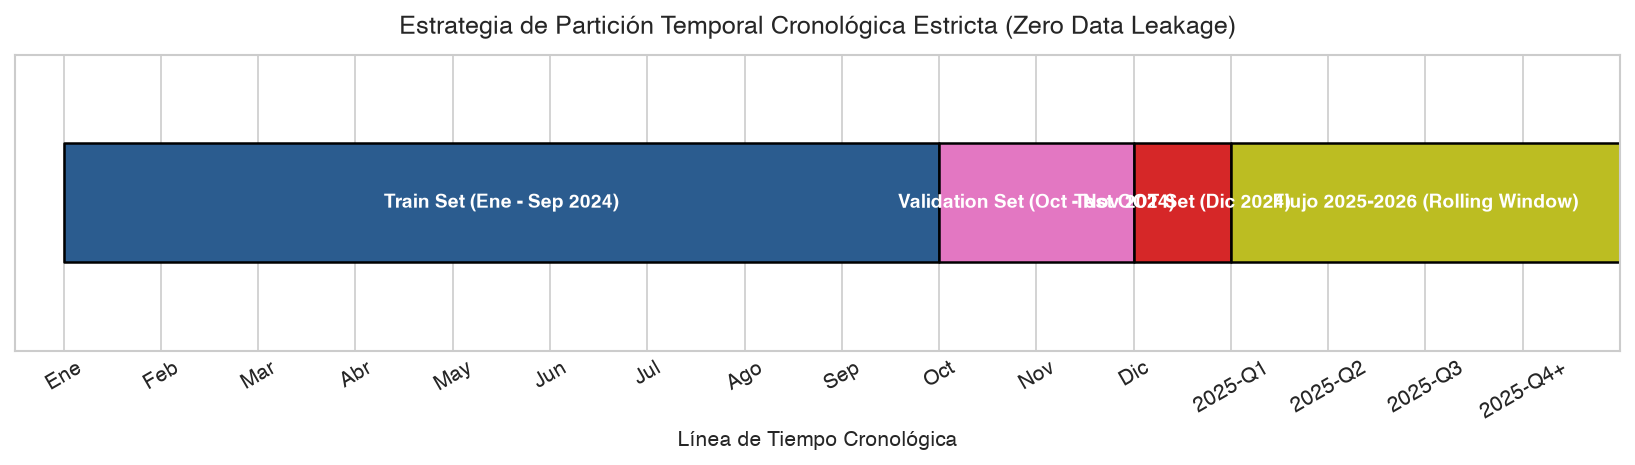

In [8]:
# Visualización de la estrategia de partición temporal
fig, ax = plt.subplots(figsize=(11, 3.2))
splits = [
    ('Train Set (Ene - Sep 2024)', 1, 9, '#2b5c8f', '75.0% - Entrenamiento de Modelos Base y Candidatos'),
    ('Validation Set (Oct - Nov 2024)', 10, 11, '#e377c2', '16.7% - Afinación de Hiperparámetros y Umbrales'),
    ('Test OOT Set (Dic 2024)', 12, 12, '#d62728', '8.3% - Evaluación Final Ciega Out-of-Time'),
    ('Flujo 2025-2026 (Rolling Window)', 13, 16, '#bcbd22', 'Monitoreo de Data Drift y Reentrenamiento Continuo')
]
y_pos = 0.5
for name, start_m, end_m, col, desc in splits:
    length = end_m - start_m + 1
    ax.broken_barh([(start_m, length)], (y_pos - 0.2, 0.4), facecolors=col, edgecolor='black', linewidth=1.2)
    ax.text(start_m + length/2, y_pos, name, ha='center', va='center', color='white', fontweight='bold', fontsize=9)
ax.set_xlim(0.5, 17)
ax.set_ylim(0, 1)
ax.set_yticks([])
ax.set_xticks(range(1, 17))
ax.set_xticklabels([
    'Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic',
    '2025-Q1', '2025-Q2', '2025-Q3', '2025-Q4+'
], rotation=30)
ax.set_xlabel('Línea de Tiempo Cronológica')
ax.set_title('Estrategia de Partición Temporal Cronológica Estricta (Zero Data Leakage)', fontsize=12, pad=10)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '05_particion_temporal_zero_leakage.png', bbox_inches='tight')
plt.show()

### Dictamen y Decisiones de Diseño: Partición Temporal y Arquitectura MLOps

> **Garantías de partición temporal certificadas:**
> 1. **Cero Fuga Temporal (*Zero Data Leakage*):** Se cumple estrictamente $\max(t_{\text{train}}) < \min(t_{\text{val}}) < \min(t_{\text{test}})$. Ningún dato futuro interviene en el entrenamiento o en el cálculo de agregaciones móviles.
> 2. **Evaluación Out-of-Time rigurosa:** Evaluar en Diciembre 2024 certifica que el modelo generaliza ante variaciones estacionales y vacacionales de fin de año.
> 3. **Compatibilidad modular:** El pipeline opera en ventanas mensuales desacopladas, facilitando la ingesta de nuevos lotes de datos.

> **Arquitectura MLOps en tres capas:**
> - **Capa 1 — Baseline Inmutable 2024 (`Dataset v1.0`):** Base de comparación científica para registrar parámetros, métricas y artefactos en MLflow Tracking (`mibici-equipo05`).
> - **Capa 2 — Backtesting y Detección de Deriva 2025 (`Dataset v1.1`):** Validación fuera de tiempo a 1 año de distancia para cuantificar degradación del modelo (*model decay*) mediante pruebas de Kolmogorov-Smirnov y Population Stability Index (PSI).
> - **Capa 3 — Flujo Continuo en Producción 2026 (`Dataset v1.2`):** Ingesta gobernada por `mibici/dataset.py` y `data/manifest.json` con política de ventana deslizante (*rolling window*) de 12 meses para reentrenamiento continuo (*Continuous Training*).

> **Inmutabilidad y verificación:**  
> Las fechas canónicas (`DATA_YEAR = 2024`, `TRAIN_DATE_RANGE`, `VAL_DATE_RANGE`, `TEST_DATE_RANGE`) están centralizadas en `mibici/config.py` y son validadas automáticamente por la suite de pruebas unitarias en `tests/test_data.py`.